In [4]:
import pandas as pd
import random
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [5]:
from tools import read_sm_file, add_risk_parameters, compute_topological_indicators, visualize_dag, compute_times, draw_random_durations, beta_pert_sample, evaluate_at_EV, simulation

In [6]:
sns.set_theme(palette='tab10',style='whitegrid',font='sans-serif')

# PSPLIB dataset
A classical benchmark for RCPSP problems

Kolisch, R., & Sprecher, A. (1997). PSPLIB-a project scheduling problem library: OR software-ORSEP operations research software exchange program. European journal of operational research, 96(1), 205-216.

## Metadata

**Network Topology parameters** Vanhoucke (2008):
- CNC   Coefficient of Network Complexity
- OS    Order Strength
- #Act	Number of activities	
- SP	Serial-Parallel Network Indicator	
- AD	Activity distribution Indicator	
- LA	Length arcs indicator	
- I5	I5 indicator	
- TF	Total float indicator	

In [7]:
# Metadata
psplib_metadata = pd.read_csv('data/psplib_dataset_metadata.txt', sep='\t',index_col=0)

In [8]:
topological_index=['#Act','CNC', 'OS','SP','AD','LA','I5','TF']

In [9]:
psplib_metadata.groupby('SubSet', group_keys=False).agg({
    '#Act':'mean',
    'FileName': 'count',
})

,#Act,FileName
SubSet,,
J120,120.0,600
J30,30.0,480
J60,60.0,480
J90,90.0,480


## Sample simulation projects (only once on completition)

100 for model selection and the rest for testing

In [ ]:
# # Only once on completion
# psplib_metadata['sample']=False
# sample_index=psplib_metadata.groupby('SubSet', group_keys=False).apply(lambda x: x.sample(n=100, replace=False)).index
# psplib_metadata.loc[sample_index,'sample']=True

In [ ]:
# psplib_metadata.loc[psplib_metadata['sample'],['SubSet','FileName']].to_csv('montecarlo\\montecarlo_project_samples.csv')

In [11]:
psplib_metadata.groupby(['SubSet','sample']).agg({
    'FileName': 'count',
})

FileName
SubSet sample          
J120   False        500
       True         100
J30    False        380
       True         100
J60    False        380
       True         100
J90    False        380
       True         100

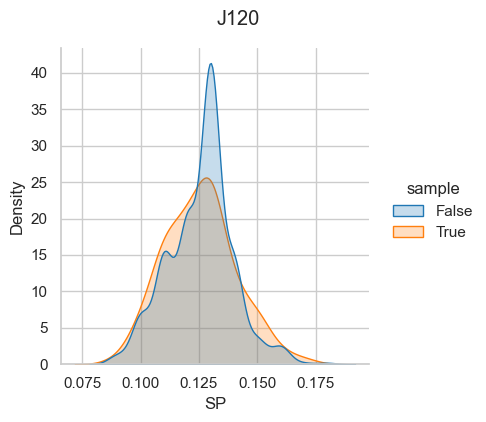

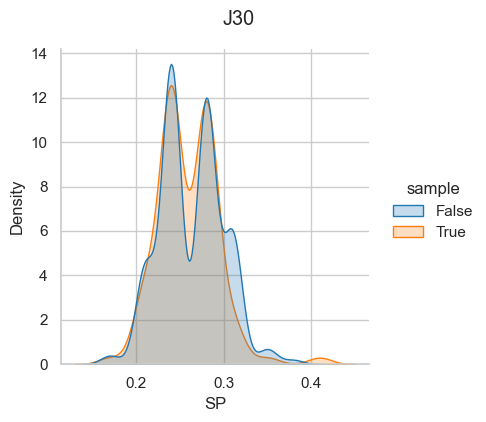

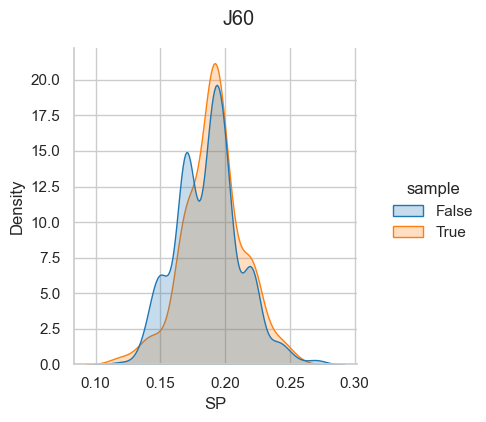

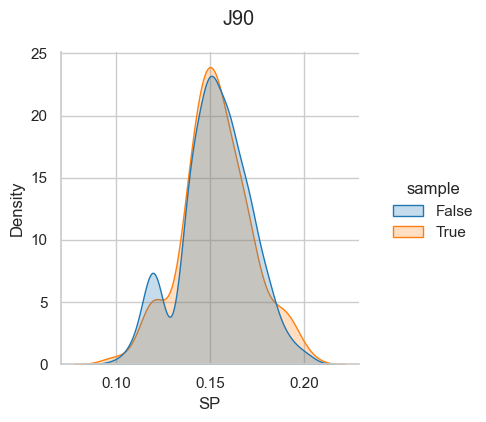

In [12]:
for s in psplib_metadata['SubSet'].unique():
    g=sns.displot(psplib_metadata[psplib_metadata['SubSet'] == s], x='SP', hue='sample', kind='kde',
                fill=True, height=4, aspect=1, common_norm=False)
    g.fig.suptitle(f'{s}', y=1.05)  

In [ ]:
# # Save metadata (only once on completion!!!!!)
# psplib_metadata.to_csv('data/psplib_dataset_metadata.txt', sep='\t')

In [ ]:
# # Only once on completion !!!!!!

# # Create a sample dataset from the PSPLIB dataset
# os.makedirs('./data/psplib_sample', exist_ok=True)

# # Copy files to the sample dataset
# for s in psplib_metadata['SubSet'].unique():
#     for file in psplib_metadata[(psplib_metadata['SubSet'] == s) & (psplib_metadata['sample']==True)]['FileName']:
#         os.replace(f'.PSPLIB/{s}/{file}', f'./data/psplib_sample/{file}')

## Checking Monte Carlo simulation for one project

In [13]:
# Metadata
psplib_metadata = pd.read_csv('data/psplib_dataset_metadata.txt', sep='\t',index_col=0)

In [92]:
# psplib_metadata[(psplib_metadata['SubSet'] == 'J30') & (psplib_metadata['sample']==True)].head(10)

In [14]:
# Project ID for the current analysis
project_id = 7558
psplib_metadata.loc[project_id,'FileName']

'j301_5.sm'

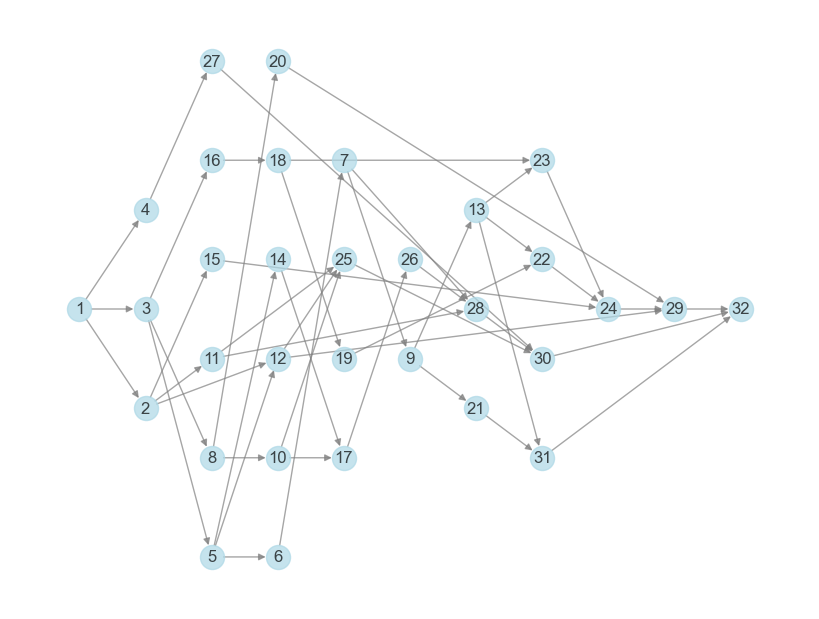

In [15]:
# Create a directed acyclic graph (DAG) from the project file
G=read_sm_file(f'data/psplib_sample/{psplib_metadata.loc[project_id,"FileName"]}')
visualize_dag(G)

In [16]:
# Check topological indices
topological_index=['#Act','CNC', 'OS','SP','AD','LA','I5','TF']
print(f"Project file: {psplib_metadata.loc[project_id,'FileName']}")
print("\nTopological metrics by Vanhoucke")
print(psplib_metadata.loc[project_id,topological_index])
print("\nTopological metrics by own calculation")
I1, CNC, OS, SP, AD, LA, I5, TF= compute_topological_indicators(G)
print(f"I1: {I1}, CNC: {CNC:0.4f}, OS: {OS:0.4f}, SP: {SP:0.4f}, AD: {AD:0.4f}, LA: {LA:0.4f}, I5: {I5:0.4f}, TF: {TF:0.4f}")

Project file: j301_5.sm

Topological metrics by Vanhoucke
#Act      30
CNC      1.4
OS      0.32
SP      0.28
AD      0.36
LA      0.05
I5       0.7
TF      0.38
Name: 7558, dtype: object

Topological metrics by own calculation
I1: 30, CNC: 1.4000, OS: 0.3172, SP: 0.2759, AD: 0.3571, LA: 0.0488, I5: 0.6952, TF: 0.3810


In [8]:
# Monte Carlo Simulatio flow

# (1) Create a directed acyclic graph (DAG) from the project file
G=read_sm_file(f'data/psplib_sample/{psplib_metadata.loc[project_id,"FileName"]}')

# (2) Add beta-PERT distribution parameters
# Assume a skewed left distribution for the risk relative to baseline duration
add_risk_parameters(G, optim=0.8, mostprob=1.1, pessim=1.2)

# (3) Set up the control point at EV=15%
evaluate_at_EV(G, EV=0.15, Ti=0, N=10000)  

# (4) Monte Carlo simulaton from the control point
# draw_random_durations(G,control=True)
simulation(G, project_name=psplib_metadata.loc[project_id,'FileName'].replace('.sm',''), experiment='00test', control=True, Nruns=1000, echo=False)


In [9]:
# Read simulation results
simulation_results = pd.read_csv('./montecarlo/'+psplib_metadata.loc[project_id,'FileName'].replace('.sm','')+'_simulation_' + '00test'+ '.csv',index_col=0)

In [10]:
import random

In [11]:
# Distribution statistics of ended jobs at the control point
for c in [f'duration{n}' for n in G.nodes() if G.nodes[n]['done%']>=1][1:]:
    print(c, f'mean: {simulation_results[c].mean():.2f}, std: {simulation_results[c].std():.2f}')

duration3 mean: 4.27, std: 0.00
duration4 mean: 2.13, std: 0.00
duration5 mean: 1.07, std: 0.00


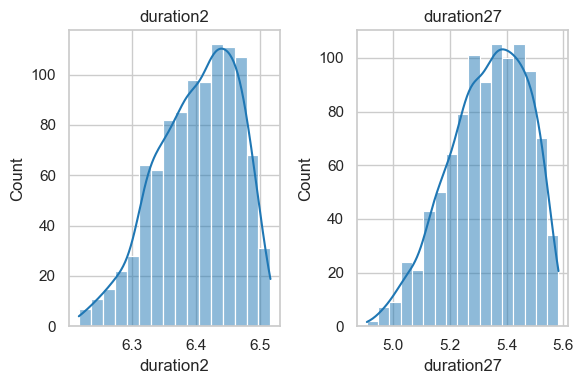

In [12]:
#  Distribution statistics of started but incomplete activities at the control point
vars = [f'duration{n}' for n in G.nodes() if (G.nodes[n]['done%']>0.5) and (G.nodes[n]['done%']<1)]
m=len(vars)
fig, axes = plt.subplots(1, m, figsize=(6, 4))
for ax, col in zip(axes.flat, vars):
    sns.histplot(simulation_results[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

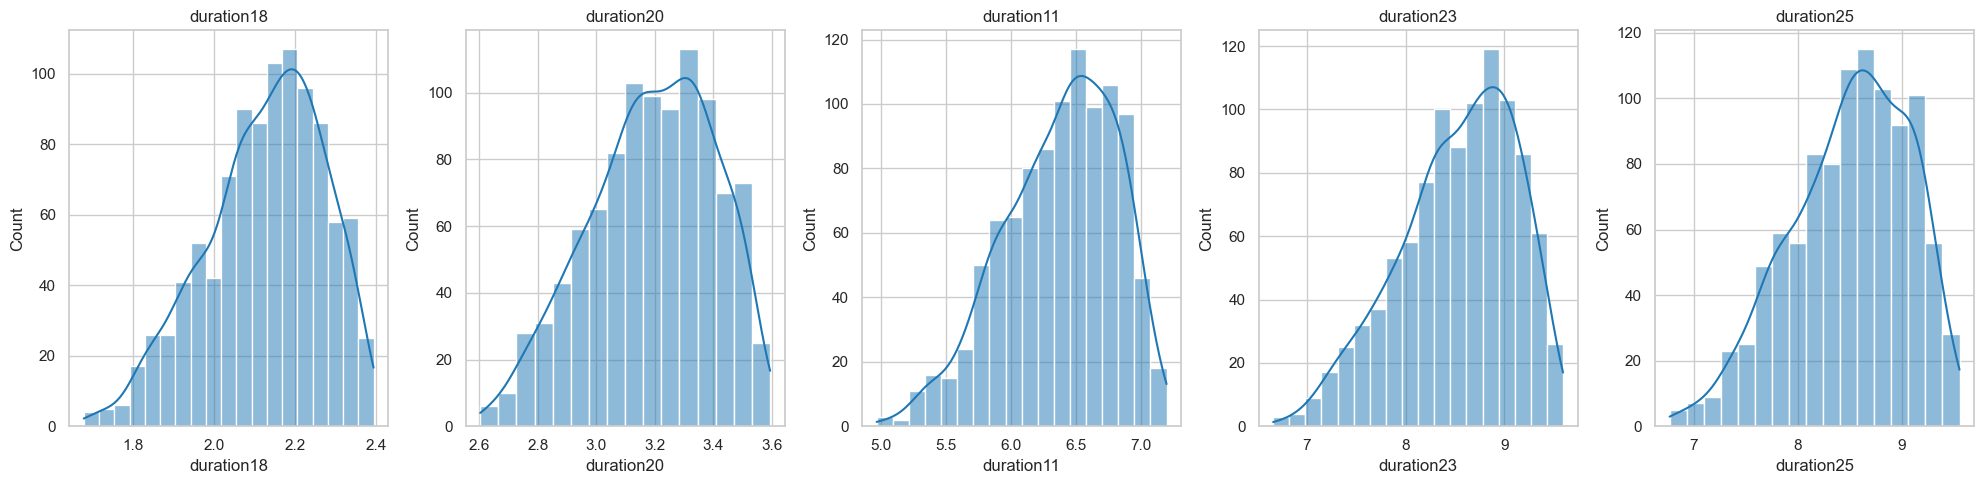

In [13]:
#  Distribution statistics of not started activities at the control point
vars = random.sample([f'duration{n}' for n in G.nodes() if G.nodes[n]['done%']==0][:-1],5)
m=len(vars)
fig, axes = plt.subplots(1, m, figsize=(20, 5))
for ax, col in zip(axes.flat, vars):
    sns.histplot(simulation_results[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Monte Carlo simulations

In [14]:
for project_id in psplib_metadata[psplib_metadata['sample']].index:
        
    # (1) Create a directed acyclic graph (DAG) from the project file
    G=read_sm_file(f'data/psplib_sample/{psplib_metadata.loc[project_id,"FileName"]}')

    # (2) Add beta-PERT distribution parameters
    # Assume a skewed left distribution for the risk relative to baseline duration
    add_risk_parameters(G, optim=0.8, mostprob=1.1, pessim=1.2)

    # (3) Set up the control point at EV=15%
    evaluate_at_EV(G, EV=0.15, Ti=0, N=10000)  

    # (4) Monte Carlo simulaton from the control point
    # draw_random_durations(G,control=True)
    simulation(G, project_name=psplib_metadata.loc[project_id,'FileName'].replace('.sm',''), experiment='01', control=True, Nruns=10000, echo=True)


Starting simulation of j1201_3...
Starting simulation of j1201_4...
Starting simulation of j1201_9...
Starting simulation of j1202_2...
Starting simulation of j1203_1...
Starting simulation of j1204_7...
Starting simulation of j1204_8...
Starting simulation of j1204_9...
Starting simulation of j1205_2...
Starting simulation of j1206_10...
Starting simulation of j1207_3...
Starting simulation of j1208_1...
Starting simulation of j1209_7...
Starting simulation of j12010_6...
Starting simulation of j12010_7...
Starting simulation of j12011_2...
Starting simulation of j12012_3...
Starting simulation of j12012_4...
Starting simulation of j12013_1...
Starting simulation of j12013_9...
Starting simulation of j12013_10...
Starting simulation of j12014_5...
Starting simulation of j12014_7...
Starting simulation of j12014_10...
Starting simulation of j12015_2...
Starting simulation of j12016_3...
Starting simulation of j12016_7...
Starting simulation of j12018_3...
Starting simulation of j12018_

In [17]:
for subset in ["j30","j60","j90","j120"]:
    print(f'{subset}: {len([f for f in os.listdir('montecarlo') if f.startswith(subset)])}')

j30: 100
j60: 100
j90: 100
j120: 100


## Model selection and model evaluation dataset

In [18]:
# Metadata
psplib_metadata = pd.read_csv('data/psplib_dataset_metadata.txt', sep='\t',index_col=0)

In [22]:
seed=112358
random.seed(seed)

In [ ]:
psplib_metadata['model_selection']=False
for subset in psplib_metadata['SubSet'].unique():
    psplib_metadata.loc[ psplib_metadata[(psplib_metadata['sample'] == True) & (psplib_metadata['SubSet'] == subset)].sample(10, random_state=seed).index, 'model_selection'] = True

In [19]:
psplib_metadata[psplib_metadata['sample']==True].groupby(['SubSet']).agg({'sample':'sum','model_selection':'sum'})

,sample,model_selection
SubSet,,
J120,100,10
J30,100,10
J60,100,10
J90,100,10


In [29]:
# Sample for model selection of the J120 subset
psplib_metadata.loc[(psplib_metadata['SubSet']=='J120') & (psplib_metadata['model_selection']==True),'FileName']

ID
6957      j1201_4.sm
6992      j1204_9.sm
7093    j12014_10.sm
7146     j12020_3.sm
7173    j12022_10.sm
7246     j12030_3.sm
7304     j12036_1.sm
7323    j12037_10.sm
7337     j12039_4.sm
7405     j12046_2.sm
Name: FileName, dtype: object

In [ ]:
# psplib_metadata.loc[(psplib_metadata['sample']==True) & (psplib_metadata['model_selection']==True),['SubSet','FileName','sample','model_selection']].to_csv('montecarlo\\project_selection.csv')
# psplib_metadata.loc[(psplib_metadata['sample']==True) & (psplib_metadata['model_selection']==False),['SubSet','FileName','sample','model_selection']].to_csv('montecarlo\\project_test.csv')

## Cross-Validation sets
Indexes for all datasets (model selection and model evaluation)

In [ ]:
# Sample 20% of a simulation run for testing (the rest will be used for training)
# The number of runs is 
Nruns=10000
random.seed(seed)
# pd.DataFrame(random.sample(range(Nruns),int(Nruns*0.2)), columns=['test_runs']).to_csv('montecarlo\\test_runs.csv', index=False)